In [1]:
import numpy as np
from scipy.optimize import root_scalar
import matplotlib.pyplot as plt

## Line-tension (LT) model
First define the functions for the LT model, then use the kink-pair formation enthalpy ΔH*(0) and the Peierls stress τ_P from the atomistic (NEB / molecular statics) calculations to determine R = Γ_c/Γ_0 and α, and finally compute the predicted ΔH*(τ) curve.

In [2]:
# -----------------------------
# Define functions:
# -----------------------------
#
# Vp(x) = (Delta E_p / 2) * (1 + alpha/4 + cos(2*pi*x/a) - alpha/4*cos(4*pi*x/a))
# See Eq. (12) in the paper.
# -----------------------------
def gamma_func(x, Gamma_c, Gamma_0, alpha, a):
    '''
    x: input variable
    Gamma_0: DEp/(R-1)
    Gamma_c: Gamma_0 * R
    alpha: fitting parameter
    a: lattice periodicity
    '''
    return (
        (Gamma_c + Gamma_0) / 2
        + (Gamma_c - Gamma_0) / 2
        * (
            alpha / 4
            + np.cos(2 * np.pi * x / a)
            - alpha / 4 * np.cos(4 * np.pi * x / a)
        )
    )


# Find the first root of fun in [x_left, x_right] by scanning for sign changes
def find_first_root_in_interval(fun, x_left, x_right, nscan=10000, tol=1e-10):
    """
    Find the first root of fun in [x_left, x_right] by scanning for sign changes
    and then refining with brentq.
    """
    xs = np.linspace(x_left, x_right, nscan)
    vals = np.array([fun(x) for x in xs])

    for i in range(len(xs) - 1):
        f1 = vals[i]
        f2 = vals[i + 1]

        if np.isnan(f1) or np.isnan(f2):
            continue

        if abs(f1) < tol:
            return xs[i]

        if f1 * f2 < 0:
            sol = root_scalar(fun, bracket=[xs[i], xs[i + 1]], method="brentq")
            if sol.converged:
                return sol.root

    raise RuntimeError(f"No root found in [{x_left}, {x_right}].")

def find_nontrivial_root_in_interval(fun, x_left, x_right, nscan=20000):
    xs = np.linspace(x_left, x_right, nscan)
    vals = np.array([fun(x) for x in xs])

    for i in range(len(xs) - 1):
        f1 = vals[i]
        f2 = vals[i + 1]

        if np.isnan(f1) or np.isnan(f2):
            continue

        # only use sign change, not abs(f)<tol
        if f1 * f2 < 0:
            sol = root_scalar(fun, bracket=[xs[i], xs[i + 1]], method="brentq")
            if sol.converged:
                return sol.root

    raise RuntimeError(f"No nontrivial root found in [{x_left}, {x_right}].")

def LT_model(DEp_b, R, b, alpha):
    # -----------------------------
    # Constants
    # -----------------------------
    eVtoGPa = 160.21766208
    Nsteps = 10000

    a_b = 2 * b / np.sqrt(3)
    a = np.sqrt(2 / 3) * a_b
    DEp = DEp_b / b  # Peierls potential energy 
    Gamma_0 = DEp / (R - 1)
    Gamma_c = Gamma_0 * R

    if abs(alpha) != 0:
        tau_P = (
            np.pi * (Gamma_c - Gamma_0)
            / (16 * abs(alpha) * a * b)
            * (3 + np.sqrt(1 + 8 * alpha**2))
            * np.sqrt(8 * alpha**2 - 2 + 2 * np.sqrt(1 + 8 * alpha**2))
        )
    else:
        tau_P = np.pi * (Gamma_c - Gamma_0) / (a * b)

    K = np.arange(0.001, 0.999, 0.01)

    # -----------------------------
    # Arrays for results
    # -----------------------------
    y0 = np.zeros(len(K))
    lambda_c = np.zeros(len(K))
    Dy = np.zeros(len(K))
    Gamma_y0 = np.zeros(len(K))
    Un = np.zeros(len(K))

    # -----------------------------
    # Main loop
    # -----------------------------
    for i, Ki in enumerate(K):

        # Step 1 - y0
        def fun_y(y):
            return (
                Ki * tau_P * b
                + np.pi / a
                * (Gamma_c - Gamma_0)
                * np.sin(2 * np.pi * y / a)
                * (1 - alpha * np.cos(2 * np.pi * y / a))
            )

        # choose the left root in [-a/2, 0], matching the MATLAB behavior near -a/2
        y0[i] = find_first_root_in_interval(fun_y, -a / 2, 0.0)

        # Step 2 - lambda_c
        def fun_lambda(lam):
            return (
                (Gamma_c - Gamma_0) / 2
                * (np.cos(2 * np.pi * lam / a) - np.cos(2 * np.pi * y0[i] / a))
                - alpha / 8
                * (Gamma_c - Gamma_0)
                * (np.cos(4 * np.pi * lam / a) - np.cos(4 * np.pi * y0[i] / a))
                - Ki * tau_P * b * (lam - y0[i])
            )

        # avoid the trivial root lambda = y0
        #eps = 1e-4
        #lambda_c[i] = find_first_root_in_interval(fun_lambda, y0[i] + eps, a / 2)

        delta = max(1e-3 * a, 1e-4)
        lambda_c[i] = find_nontrivial_root_in_interval(fun_lambda, y0[i] + delta, a / 2)

        # Step 3 - kink-pair nucleation energy
        Dy[i] = (lambda_c[i] - y0[i]) / Nsteps
        Gamma_y0[i] = gamma_func(y0[i], Gamma_c, Gamma_0, alpha, a)

        Un_d = 0.0
        for j in range(Nsteps):
            y01 = y0[i] + j * Dy[i]
            y02 = y0[i] + (j + 1) * Dy[i]

            Gamma_y01 = gamma_func(y01, Gamma_c, Gamma_0, alpha, a)
            Gamma_y02 = gamma_func(y02, Gamma_c, Gamma_0, alpha, a)

            rad1 = Gamma_y01**2 - (Ki * tau_P * b * (y01 - y0[i]) + Gamma_y0[i]) ** 2
            rad2 = Gamma_y02**2 - (Ki * tau_P * b * (y02 - y0[i]) + Gamma_y0[i]) ** 2

            tol = 1e-8

            if rad1 < -tol:
                print(f"Warning: rad1 significantly negative at i={i}, j={j}: {rad1}")
            if rad2 < -tol:
                print(f"Warning: rad2 significantly negative at i={i}, j={j}: {rad2}")

            A1 = np.sqrt(max(rad1, 0.0))
            A2 = np.sqrt(max(rad2, 0.0))

            Un_d += Dy[i] * (A1 + A2)

        Un[i] = Un_d

    print("Gamma_0 =", Gamma_0)
    print("Gamma_c =", Gamma_c)
    print("tau_P   =", tau_P)

    return K*tau_P*eVtoGPa, Un

def get_alpha(DEp_b, b, R, tauP_fixed, branch="negative"):
    """
    Solve alpha from tauP_fixed = tau_P(alpha).

    Parameters
    ----------
    DEp_b : float
        Peierls barrier per b in eV
    b : float
        Burgers vector in Angstrom
    R : float
        Gamma_c / Gamma_0
    tauP_fixed : float
        Target tau_P value
    branch : str
        "negative", "positive", or "both"

    Returns
    -------
    float or tuple
        alpha value, or (alpha_pos, alpha_neg) if branch="both"
    """

    a_b = 2 * b / np.sqrt(3)
    a = np.sqrt(2 / 3) * a_b

    DEp = DEp_b / b
    Gamma_0 = DEp / (R - 1)
    Gamma_c = Gamma_0 * R

    def tauP_from_alpha(alpha):
        alpha_abs = abs(alpha)

        if alpha_abs < 1e-14:
            return np.pi * (Gamma_c - Gamma_0) / (a * b)

        return (
            np.pi * (Gamma_c - Gamma_0)
            / (16 * alpha_abs * a * b)
            * (3 + np.sqrt(1 + 8 * alpha_abs**2))
            * np.sqrt(8 * alpha_abs**2 - 2 + 2 * np.sqrt(1 + 8 * alpha_abs**2))
        )

    tau0 = tauP_from_alpha(0.0)

    if np.isclose(tauP_fixed, tau0, rtol=1e-12, atol=1e-15):
        alpha_abs = 0.0
    else:
        def f(alpha_abs):
            return tauP_from_alpha(alpha_abs) - tauP_fixed

        if tauP_fixed < tau0:
            raise ValueError(
                f"No real solution: tauP_fixed ({tauP_fixed}) is smaller than tauP(alpha=0) ({tau0})."
            )

        lo = 1e-12
        hi = 1.0
        while f(hi) < 0:
            hi *= 2
            if hi > 1e6:
                raise RuntimeError("Could not bracket the root for |alpha|.")

        sol = root_scalar(f, bracket=[lo, hi], method="brentq")

        if not sol.converged:
            raise RuntimeError("Root finding failed.")

        alpha_abs = sol.root

    if branch == "negative":
        return -alpha_abs
    elif branch == "positive":
        return alpha_abs
    elif branch == "both":
        return alpha_abs, -alpha_abs
    else:
        raise ValueError("branch must be 'negative', 'positive', or 'both'")

def get_R(Ek, DEp_b, b, tau_P_md, R_low=1.0001, R_high=1.05, Nsteps_k=10000):
    a_b = 2 * b / np.sqrt(3)
    a = np.sqrt(2 / 3) * a_b
    DEp = DEp_b / b

    def predicted_Ek(R):
        alpha = get_alpha(DEp_b, b, R, tau_P_md, branch="negative")
        Gamma_0 = DEp / (R - 1)
        Gamma_c = Gamma_0 * R

        Dy_k = a / Nsteps_k
        Uk = 0.0

        for j in range(Nsteps_k):
            y01_k = -a / 2 + j * Dy_k
            y02_k = -a / 2 + (j + 1) * Dy_k

            Gamma_y01_k = gamma_func(y01_k, Gamma_c, Gamma_0, alpha, a)
            Gamma_y02_k = gamma_func(y02_k, Gamma_c, Gamma_0, alpha, a)

            rad1 = max((Gamma_y01_k / Gamma_0) ** 2 - 1, 0.0)
            rad2 = max((Gamma_y02_k / Gamma_0) ** 2 - 1, 0.0)

            Uk += Gamma_0 / 2 * Dy_k * (np.sqrt(rad1) + np.sqrt(rad2))

        return 2 * Uk

    def f(R):
        return predicted_Ek(R) - Ek

    sol = root_scalar(f, bracket=[R_low, R_high], method="brentq")

    if not sol.converged:
        raise RuntimeError("Failed to find R")

    R = sol.root
    alpha = get_alpha(DEp_b, b, R, tau_P_md, branch="negative")

    print("--------------------------------------------")
    print("Found R:", R)
    print("Found alpha:", alpha)
    print("Predicted kink pair formation energy:", predicted_Ek(R))
    print("MD kink pair formation energy:", Ek)
    print("Difference:", predicted_Ek(R) - Ek)

    return R, alpha

def plot_LT_model(Ek, DEp_b, a0, tauP_fixed):

    eVtoGPa = 160.21766208
    b = a0 * np.sqrt(3) / 2  # burgers vector
    tau_P_md = tauP_fixed * (1/eVtoGPa)

    R, alpha = get_R(Ek, DEp_b, b, tau_P_md, R_low=1.00001, R_high=1.03)
    LT_tau, LT_E = LT_model(DEp_b, R, b, alpha)

    plt.figure(figsize=(5, 3))
    plt.plot(LT_tau, LT_E, color='orange', linewidth=2, label='LT model')
    plt.xlabel('τ, GPa', fontsize=18)
    plt.ylabel('ΔH*(τ), eV', fontsize=18)
    plt.legend(fontsize=14)
    plt.grid(True, alpha=0.3)
    plt.show()

    return LT_tau, LT_E, R, alpha

## Data for Niobium (Nb) at 0K, from MD simulations:

--------------------------------------------
Found R: 1.0061852167305678
Found alpha: -1.1137727733738938
Predicted kink pair formation energy: 0.7220000000289161
MD kink pair formation energy: 0.722
Difference: 2.891609174326959e-11
Gamma_0 = 2.5338075437384924
Gamma_c = 2.5494796925500625
tau_P   = 0.008582075048089484


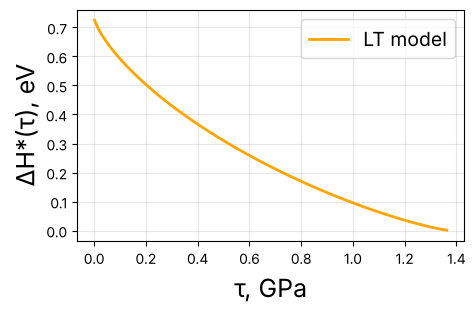

In [3]:
# add input
Ek_Nb = 0.722 # Kink pair formation energy in eV
DEp_b_Nb = 0.0449 # Peierls energy barrier in eV
a0_Nb = 3.308165 # equilibrium lattice constant in Angstrom
tauP_fixed_Nb = 1.375 # Peierls stress in GPa

LT_tau_Nb, LT_E_Nb, R_Nb, alpha_Nb = plot_LT_model(Ek_Nb, DEp_b_Nb, a0_Nb, tauP_fixed_Nb)

## Data for Tungsten (W) at 0K, from MD simulations:

--------------------------------------------
Found R: 1.0098659006756743
Found alpha: -0.6305618157174361
Predicted kink pair formation energy: 1.488000000000002
MD kink pair formation energy: 1.488
Difference: 1.9984014443252818e-15
Gamma_0 = 3.62142423043293
Gamma_c = 3.6571528421948614
tau_P   = 0.017944338736914364


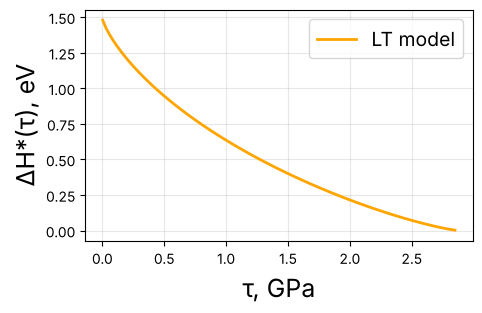

In [4]:
Ek_W = 1.488  # Kink pair formation energy in eV
DEp_b_W = 0.0986 # Peierls energy barrier in eV
a0_W = 3.186619 # equilibrium lattice constant in Angstrom
tauP_fixed_W = 2.875 # Peierls stress in GPa

LT_tau_W, LT_E_W, R_W, alpha_W = plot_LT_model(Ek_W, DEp_b_W, a0_W, tauP_fixed_W)

## Data for molybdenum (Mo) at 0K, from MD simulations:

--------------------------------------------
Found R: 1.0077534135714192
Found alpha: -0.2032820114715386
Predicted kink pair formation energy: 1.0729999999999942
MD kink pair formation energy: 1.073
Difference: -5.773159728050814e-15
Gamma_0 = 2.71169995400761
Gamma_c = 2.7327248852326296
tau_P   = 0.009518301416971658


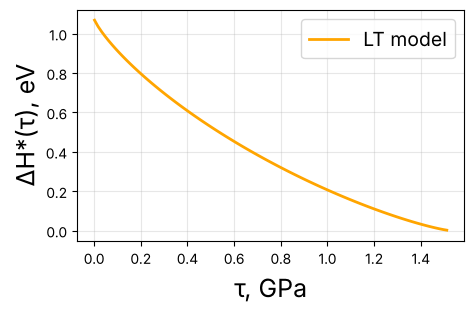

In [5]:
Ek_Mo = 1.073  # Kink pair formation energy in eV
DEp_b_Mo = 0.0576 # Peierls energy barrier in eV
a0_Mo = 3.163423 # equilibrium lattice constant in Angstrom
tauP_fixed_Mo = 1.525 # Peierls stress in GPa

LT_tau_Mo, LT_E_Mo, R_Mo, alpha_Mo = plot_LT_model(Ek_Mo, DEp_b_Mo, a0_Mo, tauP_fixed_Mo)

## Kocks' law fit
Fit p and q in ΔH*(τ) = ΔH*(0) [1 − (τ/τ_P)^p]^q [Eq. (8)] to the 3D NEB kink-pair enthalpies, with ΔH*(0) and τ_P fixed to the ACE-2025 values (Table V). The resulting p and q are those reported in Table VI.

In [6]:
from scipy.optimize import curve_fit

# 3D NEB kink-pair nucleation enthalpies (ACE-2025, T = 0 K): applied stress (GPa), enthalpy (eV)
neb_data = {
    "Nb": np.array([[0.0, 0.72178482], [0.2, 0.51635834], [0.4, 0.36512319],
                    [0.9, 0.10385086], [1.0, 0.07732844]]),
    "Mo": np.array([[0.0, 1.07316402], [0.2, 0.80152705], [0.4, 0.62943982],
                    [0.6, 0.48743625], [0.8, 0.35961642], [1.0, 0.23374758],
                    [1.3, 0.08102985]]),
    "W":  np.array([[0.0, 1.48810633], [0.2, 1.24874902], [0.4, 1.06808233],
                    [0.8, 0.75341177], [1.2, 0.51927512], [1.4, 0.42987924],
                    [2.0, 0.16956976], [2.4, 0.06036679], [2.6, 0.02078987]]),
}

# Fixed parameters: Delta H*(0) (eV) and tau_P (GPa)
kocks_fixed = {"Nb": (Ek_Nb, tauP_fixed_Nb), "Mo": (Ek_Mo, tauP_fixed_Mo), "W": (Ek_W, tauP_fixed_W)}

def fit_p_q(tau, H, H0, tauP, p0=1.0, q0=1.0):
    """Fit p and q in H*(tau) = H0 * [1 - (tau/tauP)^p]^q."""
    def model(t, p, q):
        bracket = np.clip(1 - (t / tauP) ** p, 1e-10, None)
        return H0 * bracket ** q
    popt, _ = curve_fit(model, tau, H, p0=[p0, q0], bounds=(0, np.inf))
    return popt[0], popt[1]

kocks_pq = {}
for el, data in neb_data.items():
    H0, tauP = kocks_fixed[el]
    p, q = fit_p_q(data[:, 0], data[:, 1], H0, tauP)
    kocks_pq[el] = (p, q)
    print(f"{el}: H*(0) = {H0:.3f} eV, tau_P = {tauP:.3f} GPa -> p = {p:.3f}, q = {q:.3f}")

Nb: H*(0) = 0.722 eV, tau_P = 1.375 GPa -> p = 0.865, q = 1.613
Mo: H*(0) = 1.073 eV, tau_P = 1.525 GPa -> p = 0.742, q = 1.149
W: H*(0) = 1.488 eV, tau_P = 2.875 GPa -> p = 0.854, q = 1.633


## Summary and comparison (Fig. 11 and Table VI)

           p       q     alpha
Nb     0.865   1.613    -1.114
Mo     0.742   1.149    -0.203
W      0.854   1.633    -0.631


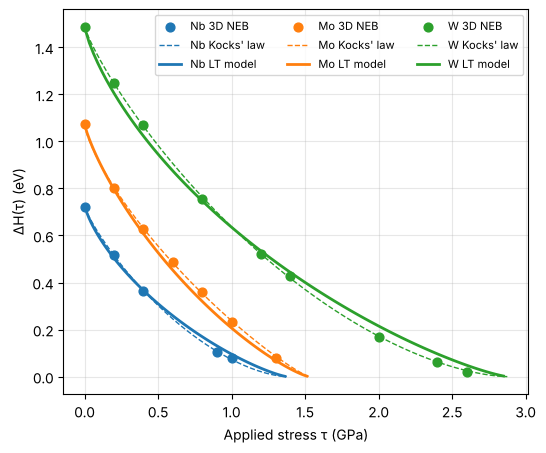

In [7]:
colors = {"Nb": "#1f77b4", "Mo": "#ff7f0e", "W": "#2ca02c"}
LT_curves = {"Nb": (LT_tau_Nb, LT_E_Nb), "Mo": (LT_tau_Mo, LT_E_Mo), "W": (LT_tau_W, LT_E_W)}
alphas = {"Nb": alpha_Nb, "Mo": alpha_Mo, "W": alpha_W}

print(f"{'':4s}{'p':>8s}{'q':>8s}{'alpha':>10s}")
for el in ["Nb", "Mo", "W"]:
    p, q = kocks_pq[el]
    print(f"{el:4s}{p:8.3f}{q:8.3f}{alphas[el]:10.3f}")

fig, ax = plt.subplots(figsize=(6, 5))
for el in ["Nb", "Mo", "W"]:
    H0, tauP = kocks_fixed[el]
    p, q = kocks_pq[el]
    t = np.linspace(0, tauP, 300)
    ax.scatter(neb_data[el][:, 0], neb_data[el][:, 1], color=colors[el], s=40, zorder=5,
               label=f"{el} 3D NEB")
    ax.plot(t, H0 * np.clip(1 - (t / tauP) ** p, 0, None) ** q, "--", color=colors[el], lw=1,
            label=f"{el} Kocks' law")
    ax.plot(*LT_curves[el], color=colors[el], lw=2, label=f"{el} LT model")
ax.set_xlabel("Applied stress τ (GPa)")
ax.set_ylabel("ΔH(τ) (eV)")
ax.grid(True, alpha=0.3)
ax.legend(fontsize=8, ncol=3)
plt.show()